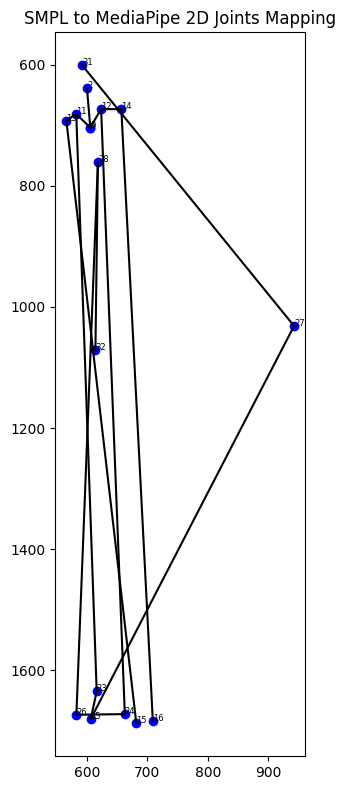

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# === Step 1: Define your 49 SMPL 2D joints ===
smpl_2d_joints = np.array([
    [605.922, 703.8489],
    [618.4566, 761.671],
    [511.9262, 795.56134],
    [401.187, 839.6416],
    [361.59317, 770.1472],
    [724.54663, 807.17004],
    [833.153, 933.39935],
    [942.43054, 1031.451],
    [619.1444, 1084.9391],
    [585.87317, 1142.7559],
    [587.4215, 1382.2195],
    [600.20874, 1642.6659],
    [658.3543, 1140.268],
    [671.5297, 1380.5096],
    [632.6316, 1622.1525],
    [582.7757, 681.5791],
    [623.8282, 673.34644],
    [566.4185, 692.24146],
    [657.1958, 673.5421],
    [681.97705, 1687.7375],
    [709.21094, 1683.7183],
    [616.5002, 1635.0343],
    [662.9627, 1672.4365],
    [606.7215, 1680.4094],
    [582.9755, 1673.5309],
    [600.20874, 1642.6659],
    [587.4215, 1382.2195],
    [545.2282, 1074.0533],
    [693.2992, 1068.5697],
    [671.5297, 1380.5096],
    [632.6316, 1622.1525],
    [361.59317, 770.1472],
    [401.187, 839.6416],
    [511.9262, 795.56134],
    [724.54663, 807.17004],
    [833.153, 933.39935],
    [942.43054, 1031.451],
    [618.5079, 761.4705],
    [592.5564, 600.90924],
    [614.4286, 1070.7407],
    [618.98895, 789.93365],
    [609.0851, 910.06934],
    [618.2932, 717.2071],
    [600.4864, 638.7668],
    [605.922, 703.8489],
    [623.8282, 673.34644],
    [582.7757, 681.5791],
    [657.1958, 673.5421],
    [566.4185, 692.24146]
])

# === Step 2: Define SMPL-to-MediaPipe mapping (approximate) ===
smpl_to_mediapipe = {
    0: 0,     # Nose
    15: 11,   # Left shoulder
    16: 12,   # Right shoulder
    17: 13,   # Left elbow
    18: 14,   # Right elbow
    19: 15,   # Left wrist
    20: 16,   # Right wrist
    21: 23,   # Left knee
    22: 24,   # Right knee
    23: 25,   # Left ankle
    24: 26,   # Right ankle
    36: 27,   # Right heel
    37: 28,   # Left heel
    38: 31,   # Right foot index
    39: 32,   # Left foot index
    44: 5,    # Left eye
    43: 2,    # Right eye
}

# === Step 3: Initialize MediaPipe joints with NaNs ===
mediapipe_2d_joints = np.full((33, 2), np.nan)

# === Step 4: Map known joints from SMPL to MediaPipe ===
for smpl_idx, mp_idx in smpl_to_mediapipe.items():
    mediapipe_2d_joints[mp_idx] = smpl_2d_joints[smpl_idx]

# === Step 5: Define MediaPipe-like connections ===
mediapipe_edges = [
    (0, 11), (11, 13), (13, 15),  # Left arm
    (0, 12), (12, 14), (14, 16),  # Right arm
    (11, 23), (23, 25), (25, 27), (27, 31),  # Left leg
    (12, 24), (24, 26), (26, 28), (28, 32),  # Right leg
    (2, 0), (0, 5),                # Eyes
]

# === Step 6: Plot ===
fig, ax = plt.subplots(figsize=(6, 8))
for i, (x, y) in enumerate(mediapipe_2d_joints):
    if not np.isnan(x) and not np.isnan(y):
        ax.scatter(x, y, c='blue')
        ax.text(x, y, str(i), fontsize=6, color='black')

# Draw edges
for i, j in mediapipe_edges:
    if not np.isnan(mediapipe_2d_joints[i][0]) and not np.isnan(mediapipe_2d_joints[j][0]):
        x_coords = [mediapipe_2d_joints[i][0], mediapipe_2d_joints[j][0]]
        y_coords = [mediapipe_2d_joints[i][1], mediapipe_2d_joints[j][1]]
        ax.plot(x_coords, y_coords, c='black')

ax.invert_yaxis()
ax.set_aspect('equal')
ax.set_title("SMPL to MediaPipe 2D Joints Mapping")
plt.tight_layout()
plt.savefig("smpl_to_mediapipe_skeleton.png", dpi=300)
plt.show()


In [2]:
!curl -O https://downloads.rclone.org/rclone-current-linux-amd64.zip
!unzip rclone-current-linux-amd64.zip
!cp rclone-*-linux-amd64/rclone /usr/bin/
!chmod 755 /usr/bin/rclone

# Login to your Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Configure rclone
!rclone config


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 22.2M  100 22.2M    0     0  11.6M      0  0:00:01  0:00:01 --:--:-- 11.6M
Archive:  rclone-current-linux-amd64.zip
   creating: rclone-v1.69.3-linux-amd64/
  inflating: rclone-v1.69.3-linux-amd64/README.html  
  inflating: rclone-v1.69.3-linux-amd64/rclone  
  inflating: rclone-v1.69.3-linux-amd64/README.txt  
  inflating: rclone-v1.69.3-linux-amd64/rclone.1  
  inflating: rclone-v1.69.3-linux-amd64/git-log.txt  
cp: cannot create regular file '/usr/bin/rclone': Permission denied
chmod: cannot access '/usr/bin/rclone': No such file or directory


ModuleNotFoundError: No module named 'google.colab'